# Chapter 6 — Velocity Kinematics: The Jacobian

Chapter 5 answered *where* the gripper is: given the joint variables $\boldsymbol\theta$,
forward kinematics gives the pose $\mathbf{T}_e^0(\boldsymbol\theta)$. This chapter answers
*how fast* it moves:

> **Velocity kinematics:** given the joint variables $\boldsymbol\theta$ and the joint
> velocities $\dot{\boldsymbol\theta}$, find the linear velocity $\mathbf{v}$ and the angular
> velocity $\boldsymbol\omega$ of the gripper.

The answer is a single matrix, the **Jacobian** $\mathbf{J}(\boldsymbol\theta)$. You met its
2D version for the planar 2R arm in Chapter 3. Here we build it for any serial arm, column
by column, from the very frames that forward kinematics already computes — no new
differentiation needed. Then we put it to work: finding **singularities**, commanding
straight-line motion (**inverse velocity**), and relating gripper forces to joint torques
(**statics**).

| Section | Topic |
|---------|-------|
| 6.1 | From the 2D Jacobian to the 3D Jacobian |
| 6.2 | The column formula |
| 6.3 | Why the column formula works |
| 6.4 | Jacobian examples: planar 2R, spherical wrist, SCARA, UR5e |
| 6.5 | Singularities |
| 6.6 | Inverse velocity, and a first look at numerical inverse kinematics |
| 6.7 | Statics: $\boldsymbol\tau = \mathbf{J}^\top\mathbf{F}$ |

**Notation** (same as Chapter 5). $\mathbf{T}_i^0$ is the pose of frame $\{i\}$ relative to
the ground frame $\{0\}$. Frame $\{i\}$ is attached to link $i$ with its $z$-axis along
joint $i$. $\boldsymbol\theta = (\theta_1,\dots,\theta_n)$ collects the joint variables; for
a prismatic joint $\theta_i$ is a length, which we also write $d_i$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
import re
from ipywidgets import interact, FloatSlider
from IPython.display import display, Math
%matplotlib inline

np.set_printoptions(precision=4, suppress=True)

### Tools and robots from Chapter 5

The next cell collects the forward-kinematics tools of Chapter 5 — the basic HTMs, the
`Robot` class that implements the three-step procedure, and a frame-drawing helper — and
rebuilds the four robots we use in this chapter with the same frames and dimensions.
Run it and move on; nothing in it is new.

In [2]:
# ── Basic HTMs ─────────────────────────────────────────────────────────────────
def Trans(axis, d):
    T = np.eye(4)
    T['xyz'.index(axis), 3] = d
    return T


def Rot(axis, theta):
    c, s = np.cos(theta), np.sin(theta)
    R = {'x': [[1, 0, 0], [0, c, -s], [0, s, c]],
         'y': [[c, 0, s], [0, 1, 0], [-s, 0, c]],
         'z': [[c, -s, 0], [s, c, 0], [0, 0, 1]]}[axis]
    T = np.eye(4)
    T[:3, :3] = R
    return T


def show(M, name='M'):
    print(f'{name} =')
    print(np.round(M, 4) + 0.0)


# ── Factors and the three-step FK procedure (Chapter 5, Section 5.3) ──────────
def Tr(axis, val, tex):
    return dict(kind='trans', axis=axis, val=val, tex=rf'\mathrm{{Trans}}_{{{axis},{tex}}}')


def Rt(axis, val, tex):
    return dict(kind='rot', axis=axis, val=val, tex=rf'\mathrm{{Rot}}_{{{axis},{tex}}}')


def factor_T(f):
    return Trans(f['axis'], f['val']) if f['kind'] == 'trans' else Rot(f['axis'], f['val'])


class Robot:
    #   home   : home[i] = list of factors whose product is T_{i+1}^{i}(0)
    #   joints : list of (slider label, LaTeX symbol, 'R' or 'P', (min, max))
    #   tool   : list of factors whose product is the constant T_e^n
    def __init__(self, name, home, joints, tool):
        self.name, self.home, self.joints, self.tool = name, home, joints, tool
        self.n = len(joints)
        self.types = [j[2] for j in joints]

    def groups(self, q):
        G = []
        for i, (_, tex, jtype, _) in enumerate(self.joints):
            motion = Rt('z', q[i], tex) if jtype == 'R' else Tr('z', q[i], tex)
            G.append((str(i + 1), self.home[i] + [motion]))
        G.append(('e', self.tool))
        return G

    def frames(self, q):
        # {'0': I, '1': T_1^0, ..., 'n': T_n^0, 'e': T_e^0}
        T, out = np.eye(4), {'0': np.eye(4)}
        for name, factors in self.groups(q):
            for f in factors:
                T = T @ factor_T(f)
            out[name] = T
        return out

    def fk(self, q):
        return self.frames(q)['e']


# ── The four robots of this chapter (same frames and dimensions as Chapter 5) ──
def make_2R(L1=1.0, L2=0.7):
    return Robot('Planar 2R', home=[[], [Tr('x', L1, 'L_1')]],
                 joints=[('θ₁', r'\theta_1', 'R', (-180, 180)), ('θ₂', r'\theta_2', 'R', (-180, 180))],
                 tool=[Tr('x', L2, 'L_2')])


def make_wrist(L=0.6):
    return Robot('Spherical wrist', home=[[], [Rt('x', -np.pi/2, r'-90^\circ')], [Rt('x', np.pi/2, r'90^\circ')]],
                 joints=[('θ₁', r'\theta_1', 'R', (-180, 180)), ('θ₂', r'\theta_2', 'R', (-180, 180)),
                         ('θ₃', r'\theta_3', 'R', (-180, 180))],
                 tool=[Tr('z', L, 'L')])


def make_scara(h=0.8, L1=0.8, L2=0.6, de=0.15):
    return Robot('SCARA', home=[[Tr('z', h, 'h')], [Tr('x', L1, 'L_1')],
                                [Tr('x', L2, 'L_2'), Rt('x', np.pi, r'180^\circ')], []],
                 joints=[('θ₁', r'\theta_1', 'R', (-180, 180)), ('θ₂', r'\theta_2', 'R', (-180, 180)),
                         ('d₃', 'd_3', 'P', (0, 0.6)), ('θ₄', r'\theta_4', 'R', (-180, 180))],
                 tool=[Tr('z', de, 'd_e')])


def make_ur5e(d1=0.163, a2=0.425, a3=0.392, d4=0.134, d5=0.100, d6=0.100):
    return Robot('UR5e', home=[[Tr('z', d1, 'd_1')], [Rt('x', np.pi/2, r'90^\circ')],
                               [Tr('x', -a2, '-a_2')], [Tr('x', -a3, '-a_3')],
                               [Tr('z', d4, 'd_4'), Rt('x', np.pi/2, r'90^\circ')],
                               [Tr('z', d5, 'd_5'), Rt('x', -np.pi/2, r'-90^\circ')]],
                 joints=[(f'θ{s}', rf'\theta_{i}', 'R', (-180, 180)) for i, s in zip(range(1, 7), '₁₂₃₄₅₆')],
                 tool=[Tr('z', d6, 'd_6')])


robot_2R, robot_wrist, robot_scara, robot_ur5e = make_2R(), make_wrist(), make_scara(), make_ur5e()


# ── Drawing helpers ────────────────────────────────────────────────────────────
AXIS_COLORS = ('red', 'green', 'blue')
V_COLOR, W_COLOR = 'black', 'purple'          # linear and angular velocity arrows


def draw_frame(ax, T, name='', scale=0.3, alpha=1.0, lw=2.0):
    o = T[:3, 3]
    for i, col in enumerate(AXIS_COLORS):
        ax.quiver(*o, *(T[:3, i] * scale), color=col, alpha=alpha, linewidth=lw, arrow_length_ratio=0.2)
    if name:
        ax.text(*(o - 0.25 * scale), f'{{{name}}}', fontsize=9, fontweight='bold')


def arrow(ax, p, v, color, lw=2.5):
    if np.linalg.norm(v) > 1e-9:
        ax.quiver(*p, *v, color=color, linewidth=lw, arrow_length_ratio=0.15)


def setup_3d(ax, center=(0, 0, 0), half=1.0, view=(25, -60), title='', zhalf=None):
    c = np.asarray(center, float)
    zh = half if zhalf is None else zhalf
    ax.set_xlim(c[0] - half, c[0] + half)
    ax.set_ylim(c[1] - half, c[1] + half)
    ax.set_zlim(c[2] - zh, c[2] + zh)
    ax.set_box_aspect((1, 1, zh / half))
    ax.set_xlabel('$x_0$'); ax.set_ylabel('$y_0$'); ax.set_zlabel('$z_0$')
    ax.view_init(*view)
    if title:
        ax.set_title(title, fontsize=11)


def plot_robot(ax, robot, q, scale=0.2, alpha=1.0, axes=False):
    # Links as a polyline through the frame origins, plus frames {0} and {e}.
    # axes=True also draws every joint axis as a dashed line through o_i along z_i.
    F = robot.frames(q)
    pts = np.array([T[:3, 3] for T in F.values()])
    ax.plot(*pts.T, color='0.5', lw=6, alpha=alpha, solid_capstyle='round', zorder=0)
    ax.scatter(*pts[:-1].T, color='0.25', s=35, alpha=alpha)
    if alpha == 1.0:
        draw_frame(ax, np.eye(4), '0', scale * 1.2)
        draw_frame(ax, F['e'], 'e', scale)
    if axes:
        for i in range(robot.n):
            o, z = F[str(i + 1)][:3, 3], F[str(i + 1)][:3, 2]
            seg = np.array([o - 0.35 * z, o + 0.35 * z])
            ax.plot(*seg.T, ls='--', lw=1, color='tab:blue', alpha=0.8)
    return F


print('Robots ready:', ', '.join(r.name for r in (robot_2R, robot_wrist, robot_scara, robot_ur5e)))

Robots ready: Planar 2R, Spherical wrist, SCARA, UR5e


## 6.1  From the 2D Jacobian to the 3D Jacobian

For the planar 2R arm in Chapter 3 we differentiated the forward kinematics
$x(\boldsymbol\theta)$, $y(\boldsymbol\theta)$ with the chain rule and found

$$\begin{bmatrix}\dot x\\ \dot y\end{bmatrix} = \mathbf{J}(\boldsymbol\theta)\begin{bmatrix}\dot\theta_1\\ \dot\theta_2\end{bmatrix},
\qquad
\mathbf{J}(\boldsymbol\theta) = \begin{bmatrix}-L_1s_1 - L_2s_{12} & -L_2s_{12}\\ L_1c_1 + L_2c_{12} & L_2c_{12}\end{bmatrix}.$$

The Jacobian is a matrix that depends on the configuration $\boldsymbol\theta$, and that
maps joint velocities **linearly** to gripper velocity. Each column is the gripper velocity
produced when only that joint moves at unit speed.

In 3D the gripper has a full pose, so it has two kinds of velocity:

- the **linear velocity** $\mathbf{v} = \dot{\mathbf{o}}_e$ of the gripper point
  $\mathbf{o}_e$ (the origin of frame $\{e\}$, i.e. the last column of $\mathbf{T}_e^0$), and
- the **angular velocity** $\boldsymbol\omega$ of the gripper frame — a vector along the
  instantaneous axis of rotation (right-hand rule) whose length is the rotation rate in rad/s.

<p align="center"><img src="Fig6-01_joint_to_gripper_velocity.png" width="820"></p>

<p align="center"><i>Figure 6.1 — Joint velocities produce gripper velocity. (a) For the planar 2R arm, θ̇<sub>1</sub> and θ̇<sub>2</sub> give the tip a velocity <b>v</b> = (ẋ, ẏ) in the plane. (b) In 3D the gripper has a linear velocity <b>v</b> of its point o<sub>e</sub> and an angular velocity <b>ω</b> along its instantaneous axis of rotation.</i></p>

Both are 3-vectors expressed in the ground frame $\{0\}$. Stacking them, the 3D Jacobian is
the $6\times n$ matrix that maps the $n$ joint velocities to these six numbers:

$$\boxed{\begin{bmatrix}\mathbf{v}\\ \boldsymbol\omega\end{bmatrix}
= \mathbf{J}(\boldsymbol\theta)\,\dot{\boldsymbol\theta}
= \begin{bmatrix}\mathbf{J}_v\\ \mathbf{J}_\omega\end{bmatrix}\dot{\boldsymbol\theta},
\qquad \mathbf{J}\in\mathbb{R}^{6\times n}}$$

The top three rows $\mathbf{J}_v$ give the linear velocity; the bottom three rows
$\mathbf{J}_\omega$ give the angular velocity. As in 2D, **column $i$ of $\mathbf{J}$ is the
gripper's $(\mathbf{v},\boldsymbol\omega)$ when joint $i$ moves at unit speed and all other
joints are still.**

<p align="center"><img src="Fig6-02_Jacobian_structure.png" width="760"></p>

<p align="center"><i>Figure 6.2 — Structure of the 6×n Jacobian: one column <b>J</b><sub>i</sub> per joint. The top three rows <b>J</b><sub>v</sub> give <b>v</b>; the bottom three rows <b>J</b><sub>ω</sub> give <b>ω</b>.</i></p>

The linear part could be found exactly as in Chapter 3, by differentiating the last column
of $\mathbf{T}_e^0$. But for a 6-joint arm that expression is long (see Section 5.8), and
the angular part has no such simple formula. The next section gives a far easier way.

> **Key Takeaways — Section 6.1**
> - The Jacobian maps joint velocities to gripper velocity: $[\mathbf{v};\boldsymbol\omega] = \mathbf{J}(\boldsymbol\theta)\dot{\boldsymbol\theta}$, with $\mathbf{J}$ of size $6\times n$.
> - $\mathbf{J}_v$ (top 3 rows) gives the linear velocity of $\mathbf{o}_e$; $\mathbf{J}_\omega$ (bottom 3 rows) gives the angular velocity of the gripper.
> - Column $i$ = gripper velocity when only joint $i$ moves at unit speed.

## 6.2  The Column Formula

From the forward kinematics of Chapter 5 we already have, for every joint $i$, the frame
$\mathbf{T}_i^0$. Two of its columns are all we need:

$$\mathbf{T}_i^0 = \begin{bmatrix} \mathbf{x}_i & \mathbf{y}_i & \mathbf{z}_i & \mathbf{o}_i\\ 0&0&0&1\end{bmatrix}
\quad\Longrightarrow\quad
\begin{cases}
\mathbf{z}_i: & \text{direction of joint axis } i \text{ (column 3)}\\
\mathbf{o}_i: & \text{a point on joint axis } i \text{ (column 4)}
\end{cases}$$

This works because in Step 1 of the forward kinematics procedure we put $z_i$ along joint
$i$ and the origin $o_i$ on it. With $\mathbf{o}_e$ the gripper position (column 4 of
$\mathbf{T}_e^0$), column $i$ of the Jacobian is:

$$
\boxed{
\text{revolute joint:}\quad
\mathbf{J}_i = \begin{bmatrix}\mathbf{z}_i\times(\mathbf{o}_e - \mathbf{o}_i)\\ \mathbf{z}_i\end{bmatrix}
\qquad\qquad
\text{prismatic joint:}\quad
\mathbf{J}_i = \begin{bmatrix}\mathbf{z}_i\\ \mathbf{0}\end{bmatrix}
}
$$

and $\mathbf{J} = \begin{bmatrix}\mathbf{J}_1 & \mathbf{J}_2 & \cdots & \mathbf{J}_n\end{bmatrix}$.

**Procedure — Jacobian from forward kinematics:**
1. Run forward kinematics and keep the partial products $\mathbf{T}_1^0, \mathbf{T}_2^0, \dots, \mathbf{T}_n^0$ and $\mathbf{T}_e^0$.
2. Read off $\mathbf{z}_i$ and $\mathbf{o}_i$ (columns 3 and 4 of $\mathbf{T}_i^0$) and $\mathbf{o}_e$ (column 4 of $\mathbf{T}_e^0$).
3. Build one column per joint with the formula above and stack the columns.

<p align="center"><img src="Fig6-03_column_formula_procedure.png" width="900"></p>

<p align="center"><i>Figure 6.3 — (a) z<sub>i</sub> and o<sub>i</sub> are columns 3 and 4 of T<sub>i</sub><sup>0</sup>, and o<sub>e</sub> is column 4 of T<sub>e</sub><sup>0</sup>. (b) The three-step procedure for building the Jacobian.</i></p>

> **Note for readers of other textbooks.** Books that use the Denavit–Hartenberg convention
> place joint $i$ along $z_{i-1}$ and write the columns with $\mathbf{z}_{i-1}$ and
> $\mathbf{o}_{i-1}$. In our convention joint $i$ lies along $z_i$ of frame $\{i\}$ itself,
> so there is no index shift. Also note that $\mathbf{T}_i^0$ includes the joint's own
> $\mathrm{Rot}_{z,\theta_i}$ (or $\mathrm{Trans}_{z,d_i}$); a rotation about $z_i$ does not
> change $\mathbf{z}_i$ or $\mathbf{o}_i$, so it does not matter.

The function below is the whole procedure in code. It works for every robot built with the
`Robot` class.

In [3]:
def jacobian(robot, q):
    # Jacobian J(q), 6 x n, built column by column from the forward-kinematics frames.
    F = robot.frames(q)                        # 1. T_1^0, ..., T_n^0 and T_e^0
    o_e = F['e'][:3, 3]                        # 2. gripper position
    J = np.zeros((6, robot.n))
    for i, jtype in enumerate(robot.types):
        T_i0 = F[str(i + 1)]
        z_i, o_i = T_i0[:3, 2], T_i0[:3, 3]    # 2. joint axis direction and a point on it
        if jtype == 'R':                       # 3. one column per joint
            J[:3, i] = np.cross(z_i, o_e - o_i)
            J[3:, i] = z_i
        else:
            J[:3, i] = z_i                     #    (prismatic: angular part stays 0)
    return J


def jacobian_numeric(robot, q, h=1e-6):
    # Independent check: finite differences of the forward kinematics.
    # Linear part: d o_e/dθ_i.  Angular part: from dR/dθ_i · Rᵀ = [ω]× (the skew matrix of Chapter 4).
    q = np.asarray(q, float)
    R = robot.fk(q)[:3, :3]
    J = np.zeros((6, robot.n))
    for i in range(robot.n):
        dq = np.zeros(robot.n); dq[i] = h
        Tp, Tm = robot.fk(q + dq), robot.fk(q - dq)
        J[:3, i] = (Tp[:3, 3] - Tm[:3, 3]) / (2 * h)
        W = (Tp[:3, :3] - Tm[:3, :3]) / (2 * h) @ R.T
        J[3:, i] = [W[2, 1], W[0, 2], W[1, 0]]
    return J


# Try it on the SCARA at an arbitrary configuration
q = [np.radians(30), np.radians(45), 0.2, np.radians(-60)]
J = jacobian(robot_scara, q)
show(J, 'J (SCARA)')
print('\nMatches finite differences of the FK?', np.allclose(J, jacobian_numeric(robot_scara, q), atol=1e-6))

J (SCARA) =
[[-0.9796 -0.5796  0.      0.    ]
 [ 0.8481  0.1553  0.      0.    ]
 [ 0.      0.     -1.      0.    ]
 [ 0.      0.      0.      0.    ]
 [ 0.      0.      0.      0.    ]
 [ 1.      1.      0.     -1.    ]]

Matches finite differences of the FK? True


> **Key Takeaways — Section 6.2**
> - Everything the Jacobian needs is already inside the forward-kinematics frames: $\mathbf{z}_i$ and $\mathbf{o}_i$ from $\mathbf{T}_i^0$, $\mathbf{o}_e$ from $\mathbf{T}_e^0$.
> - Revolute: $\mathbf{J}_i = [\mathbf{z}_i\times(\mathbf{o}_e-\mathbf{o}_i);\ \mathbf{z}_i]$. Prismatic: $\mathbf{J}_i = [\mathbf{z}_i;\ \mathbf{0}]$.
> - No differentiation is needed — just cross products of vectors read off the frames.

## 6.3  Why the Column Formula Works

We only need three facts from introductory physics.

**1. Only joint $i$ moves (revolute).** Freeze every joint except joint $i$. Everything
outboard of joint $i$ — including the gripper — now turns as one rigid body about the
fixed axis through $\mathbf{o}_i$ along $\mathbf{z}_i$, at rate $\dot\theta_i$. Its angular
velocity is therefore $\boldsymbol\omega = \dot\theta_i\,\mathbf{z}_i$, and the gripper point
moves on a **circle** around that axis. For a point on a body rotating about a fixed axis,
physics gives $\mathbf{v} = \boldsymbol\omega\times\mathbf{r}$, where $\mathbf{r}$ points from
any point on the axis to the moving point:

$$\mathbf{v} = \dot\theta_i\,\mathbf{z}_i\times(\mathbf{o}_e-\mathbf{o}_i),
\qquad \boldsymbol\omega = \dot\theta_i\,\mathbf{z}_i .$$

Dividing by $\dot\theta_i$ gives exactly the revolute column $\mathbf{J}_i$.
(Any point on the axis can play the role of $\mathbf{o}_i$: moving it along $\mathbf{z}_i$
changes $\mathbf{r}$ by a multiple of $\mathbf{z}_i$, and $\mathbf{z}_i\times\mathbf{z}_i = \mathbf{0}$.)

**2. Only joint $i$ moves (prismatic).** Everything outboard **slides** along
$\mathbf{z}_i$ at speed $\dot d_i$ without rotating: $\mathbf{v} = \dot d_i\,\mathbf{z}_i$,
$\boldsymbol\omega = \mathbf{0}$. That is the prismatic column.

<p align="center"><img src="Fig6-04_one_joint_revolute_prismatic.png" width="900"></p>

<p align="center"><i>Figure 6.4 — Only joint i moves. (a) Revolute: everything outboard rotates about the joint axis, so o<sub>e</sub> moves on a circle with <b>v</b> = <b>ω</b> × <b>r</b>. (b) Prismatic: everything outboard slides along z<sub>i</sub> without rotating.</i></p>

**3. All joints move: contributions add.** The gripper position is a function
$\mathbf{o}_e(\theta_1,\dots,\theta_n)$, so by the chain rule

$$\mathbf{v} = \dot{\mathbf{o}}_e = \frac{\partial\mathbf{o}_e}{\partial\theta_1}\dot\theta_1 + \cdots + \frac{\partial\mathbf{o}_e}{\partial\theta_n}\dot\theta_n ,$$

a **sum** of the one-joint-at-a-time velocities. Angular velocities about the joint axes add
the same way (a spinning turntable carrying a spinning top gives the top the sum of the two
spins), so

$$\mathbf{v} = \sum_{i=1}^n \mathbf{J}_{v,i}\,\dot\theta_i,\qquad
\boldsymbol\omega = \sum_{\text{revolute } i} \dot\theta_i\,\mathbf{z}_i
\qquad\Longleftrightarrow\qquad
\begin{bmatrix}\mathbf{v}\\ \boldsymbol\omega\end{bmatrix} = \mathbf{J}\,\dot{\boldsymbol\theta}.$$

The figure below shows fact 1 and fact 2 for the SCARA. In each panel only one joint moves:
the dotted curve is the path of the gripper point (a circle about the dashed joint axis, or
a straight line for the prismatic quill), and the black arrow is the linear part of that
joint's column, $\mathbf{J}_{v,i}$ — always tangent to the path.

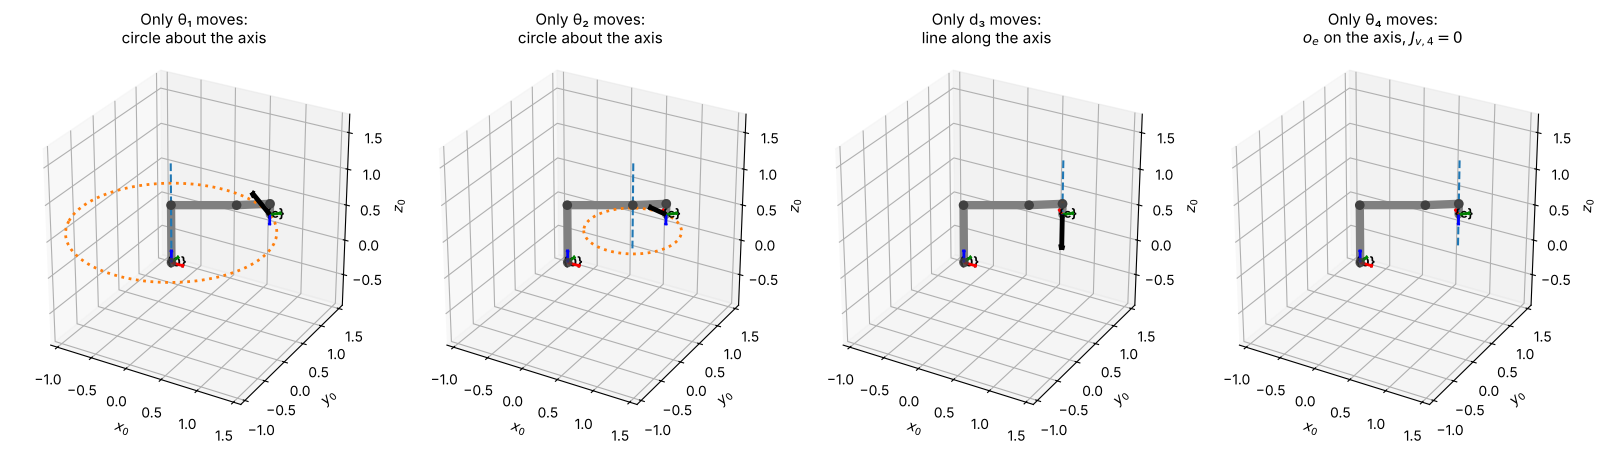

In [4]:
def one_joint_paths(robot, q, arrow_scale=0.5, figsize=(16, 4.8), **setup_kw):
    # For each joint i: the path of o_e when only joint i moves, and the column J_v,i.
    q = np.asarray(q, float)
    J = jacobian(robot, q)
    fig = plt.figure(figsize=figsize)
    for i, (label, _, jtype, (lo, hi)) in enumerate(robot.joints):
        ax = fig.add_subplot(1, robot.n, i + 1, projection='3d')
        F = plot_robot(ax, robot, q, scale=0.15)
        sweep = np.linspace(-np.pi, np.pi, 120) if jtype == 'R' else np.linspace(lo, hi, 40)
        path = []
        for s in sweep:
            qq = q.copy(); qq[i] = s
            path.append(robot.fk(qq)[:3, 3])
        ax.plot(*np.array(path).T, ':', color='tab:orange', lw=2)
        o, z = F[str(i + 1)][:3, 3], F[str(i + 1)][:3, 2]
        ax.plot(*np.array([o - 0.6 * z, o + 0.6 * z]).T, '--', color='tab:blue', lw=1.5)
        o_e = F['e'][:3, 3]
        arrow(ax, o_e, arrow_scale * J[:3, i], V_COLOR, lw=3.5)
        if np.linalg.norm(J[:3, i]) < 1e-9:
            kind = '$o_e$ on the axis, $J_{v,%d} = 0$' % (i + 1)
        else:
            kind = 'circle about the axis' if jtype == 'R' else 'line along the axis'
        setup_3d(ax, title=f'Only {label} moves:\n{kind}', **setup_kw)
    plt.tight_layout(); plt.show()


one_joint_paths(robot_scara, [np.radians(30), np.radians(45), 0.2, np.radians(-60)],
                center=(0.25, 0.25, 0.4), half=1.35, view=(28, -60))

In the last panel the gripper point lies **on** joint 4's axis, so turning joint 4 only
spins the tool: $\mathbf{J}_{v,4} = \mathbf{z}_4\times(\mathbf{o}_e-\mathbf{o}_4) = \mathbf{0}$
because $\mathbf{o}_e-\mathbf{o}_4$ is parallel to $\mathbf{z}_4$. Its column still has the
angular part $\mathbf{z}_4$.

> **Key Takeaways — Section 6.3**
> - One revolute joint moving = rigid rotation about a fixed axis: $\mathbf{v} = \boldsymbol\omega\times\mathbf{r}$ with $\boldsymbol\omega = \dot\theta_i\mathbf{z}_i$, $\mathbf{r} = \mathbf{o}_e-\mathbf{o}_i$.
> - One prismatic joint moving = pure sliding along $\mathbf{z}_i$, no rotation.
> - With all joints moving, linear velocities add (chain rule) and angular velocities add, so the columns simply stack into $\mathbf{J}$.

## 6.4  Jacobian Examples

We now apply the three-step procedure of Section 6.2 to four robots from Chapter 5: the
planar 2R arm, the spherical wrist and the SCARA by hand (checked with SymPy), and the
6-joint UR5e numerically.

### 6.4.1  Planar 2R Arm

**Step 1 — Forward kinematics.** From Section 5.4, with
$\mathbf{T}_1^0 = \mathrm{Rot}_{z,\theta_1}$,
$\mathbf{T}_2^0 = \mathrm{Rot}_{z,\theta_1}\mathrm{Trans}_{x,L_1}\mathrm{Rot}_{z,\theta_2}$ and
$\mathbf{T}_e^0 = \mathbf{T}_2^0\,\mathrm{Trans}_{x,L_2}$.

**Step 2 — Read off the vectors.**

| | $\mathbf{z}_i$ | $\mathbf{o}_i$ |
|---|---|---|
| joint 1 | $(0,0,1)$ | $(0,0,0)$ |
| joint 2 | $(0,0,1)$ | $(L_1c_1,\ L_1s_1,\ 0)$ |
| gripper | | $\mathbf{o}_e = (L_1c_1+L_2c_{12},\ L_1s_1+L_2s_{12},\ 0)$ |

**Step 3 — Columns.** Both joints are revolute. For a vector $\mathbf{r} = (r_x, r_y, 0)$,
$\ (0,0,1)\times\mathbf{r} = (-r_y,\ r_x,\ 0)$, so

$$\mathbf{J} = \begin{bmatrix}
-L_1s_1-L_2s_{12} & -L_2s_{12}\\
L_1c_1+L_2c_{12} & L_2c_{12}\\
0 & 0\\ 0 & 0\\ 0 & 0\\ 1 & 1
\end{bmatrix}.$$

The SymPy cell below carries out the three steps symbolically, and then checks the result
the Chapter 3 way: by differentiating $\mathbf{o}_e(\boldsymbol\theta)$ directly.

In [5]:
# ── SymPy versions of the basic HTMs, and a compact printer (c1 = cos θ1, s12 = sin(θ1+θ2), ...) ──
def sTrans(axis, d):
    T = sp.eye(4)
    T['xyz'.index(axis), 3] = d
    return T


def sRot(axis, t):
    c, s = sp.cos(t), sp.sin(t)
    R = {'x': [[1, 0, 0], [0, c, -s], [0, s, c]],
         'y': [[c, 0, s], [0, 1, 0], [-s, 0, c]],
         'z': [[c, -s, 0], [s, c, 0], [0, 0, 1]]}[axis]
    T = sp.eye(4)
    T[:3, :3] = sp.Matrix(R)
    return T


def show_sym(M, lhs):
    tex = sp.latex(M)

    def short(m):
        fn, inner = m.group(1), m.group(2)
        idx = re.findall(r'\\theta_\{(\d)\}', inner)
        rest = re.sub(r'\\theta_\{\d\}|\+|\s', '', inner)
        return f'{fn[0]}_{{{"".join(idx)}}}' if idx and not rest else m.group(0)

    display(Math(lhs + ' = ' + re.sub(r'\\(cos|sin)\{\\left\((.*?)\\right\)\}', short, tex)))


def sym_jacobian(T_joints, T_e, types):
    # Column formula, symbolically. T_joints = [T_1^0, ..., T_n^0], T_e = T_e^0.
    o_e = T_e[:3, 3]
    cols = []
    for T, jtype in zip(T_joints, types):
        z, o = T[:3, 2], T[:3, 3]
        top, bottom = (z.cross(o_e - o), z) if jtype == 'R' else (z, sp.zeros(3, 1))
        cols.append(sp.Matrix.vstack(top, bottom))
    return sp.simplify(sp.Matrix.hstack(*cols))

In [6]:
t1, t2, L1, L2 = sp.symbols('theta_1 theta_2 L_1 L_2', real=True)

# Step 1: forward kinematics, keeping the partial products
T10 = sRot('z', t1)
T20 = T10 * sTrans('x', L1) * sRot('z', t2)
Te0 = T20 * sTrans('x', L2)

# Steps 2-3: column formula
J_2R = sym_jacobian([T10, T20], Te0, 'RR')
show_sym(J_2R, r'\mathbf{J}')

# Check: differentiate o_e(θ) directly, as in Chapter 3
o_e = Te0[:3, 3]
J_v_direct = o_e.jacobian([t1, t2])
print('Top three rows equal d o_e / d θ ?', sp.simplify(J_2R[:3, :] - J_v_direct) == sp.zeros(3, 2))

<IPython.core.display.Math object>

Top three rows equal d o_e / d θ ? True


The top two rows are exactly the Chapter 3 Jacobian, and the formula also delivers the
angular velocity for free: $\omega_z = \dot\theta_1 + \dot\theta_2$ — the rate of change of
the gripper's heading $\theta_1+\theta_2$ that we found in Section 5.4.

Use the sliders below to set the configuration and the joint velocities. The black arrow is
$\mathbf{v}$ and the purple arrow is $\boldsymbol\omega$ (both scaled by 0.3 for display);
$\boldsymbol\omega$ always points along $z_0$ for this planar arm.

In [7]:
def explore_velocity(robot, q0=None, arrow_scale=0.3, figsize=(7, 6.5), **setup_kw):
    # Sliders for the joint variables (q0: initial values, degrees / metres) and joint velocities.
    # Shows v (black) and ω (purple) at the gripper point o_e.
    q0 = [0] * robot.n if q0 is None else q0
    sl = {}
    for i, (label, _, jtype, (lo, hi)) in enumerate(robot.joints):
        rev = jtype == 'R'
        sl[f'q{i}'] = FloatSlider(value=q0[i], min=lo, max=hi,
                                  step=1 if rev else 0.01, description=label + (' (°)' if rev else ' (m)'))
        sl[f'qd{i}'] = FloatSlider(value=0.5, min=-1, max=1, step=0.05,
                                   description=label + ('̇ (rad/s)' if rev else '̇ (m/s)'))

    def _view(**s):
        q = np.array([np.radians(s[f'q{i}']) if t == 'R' else s[f'q{i}'] for i, t in enumerate(robot.types)])
        qd = np.array([s[f'qd{i}'] for i in range(robot.n)])
        J = jacobian(robot, q)
        twist = J @ qd
        fig = plt.figure(figsize=figsize)
        ax = fig.add_subplot(111, projection='3d')
        F = plot_robot(ax, robot, q, axes=True)
        arrow(ax, F['e'][:3, 3], arrow_scale * twist[:3], V_COLOR, lw=3)
        arrow(ax, F['e'][:3, 3], arrow_scale * twist[3:], W_COLOR, lw=3)
        setup_3d(ax, title=f'{robot.name}:  v (black), ω (purple)', **setup_kw)
        plt.show()
        show(J, 'J')
        print('\n[v; ω] = J θ̇ =', np.round(twist, 3) + 0.0)

    interact(_view, **sl)


view_2R = dict(center=(0.6, 0.35, 0), half=1.1, zhalf=0.4, view=(50, -70))
explore_velocity(robot_2R, q0=[30, 60], **view_2R)

interactive(children=(FloatSlider(value=30.0, description='θ₁ (°)', max=180.0, min=-180.0, step=1.0), FloatSli…

> **Key Takeaways — Section 6.4.1**
> - For the 2R arm the column formula reproduces the Chapter 3 Jacobian in rows 1–2, and adds $\omega_z = \dot\theta_1+\dot\theta_2$ in row 6.
> - Rows 3–5 are zero: a planar arm can never move out of its plane or tilt.

### 6.4.2  3R Spherical Wrist

**Step 1 — Forward kinematics** (Section 5.5):
$\mathbf{T}_1^0 = \mathrm{Rot}_{z,\theta_1}$,
$\mathbf{T}_2^0 = \mathbf{T}_1^0\,\mathrm{Rot}_{x,-90^\circ}\mathrm{Rot}_{z,\theta_2}$,
$\mathbf{T}_3^0 = \mathbf{T}_2^0\,\mathrm{Rot}_{x,90^\circ}\mathrm{Rot}_{z,\theta_3}$,
$\mathbf{T}_e^0 = \mathbf{T}_3^0\,\mathrm{Trans}_{z,L}$.

**Step 2 — Read off the vectors.** All three axes pass through the wrist center, so
$\mathbf{o}_1 = \mathbf{o}_2 = \mathbf{o}_3 = \mathbf{0}$, and

$$\mathbf{z}_1 = \begin{bmatrix}0\\0\\1\end{bmatrix},\quad
\mathbf{z}_2 = \begin{bmatrix}-s_1\\ c_1\\ 0\end{bmatrix},\quad
\mathbf{z}_3 = \begin{bmatrix}c_1s_2\\ s_1s_2\\ c_2\end{bmatrix},\quad
\mathbf{o}_e = L\,\mathbf{z}_3 .$$

**Step 3 — Columns.** Because $\mathbf{o}_e - \mathbf{o}_3 = L\,\mathbf{z}_3$ is parallel to
$\mathbf{z}_3$, the third column has **no linear part**: rolling the last joint only spins
the gripper about its own axis.

In [8]:
t1, t2, t3, L = sp.symbols('theta_1 theta_2 theta_3 L', real=True)

T10 = sRot('z', t1)
T20 = T10 * sRot('x', -sp.pi/2) * sRot('z', t2)
T30 = T20 * sRot('x', sp.pi/2) * sRot('z', t3)
Te0 = T30 * sTrans('z', L)

J_wrist = sym_jacobian([T10, T20, T30], Te0, 'RRR')
show_sym(J_wrist, r'\mathbf{J}')

o_e = Te0[:3, 3]
print('Top three rows equal d o_e / d θ ?',
      sp.simplify(J_wrist[:3, :] - o_e.jacobian([t1, t2, t3])) == sp.zeros(3, 3))

<IPython.core.display.Math object>

Top three rows equal d o_e / d θ ? True


The bottom three rows, $\mathbf{J}_\omega = [\mathbf{z}_1\ \mathbf{z}_2\ \mathbf{z}_3]$, are the
part that matters for a wrist: its job is to **orient** the gripper. Any angular velocity
$\boldsymbol\omega$ can be produced as long as the three axes $\mathbf{z}_1,\mathbf{z}_2,\mathbf{z}_3$
are not in one plane — we return to this in Section 6.5. Notice that the angular part
could not have been found by differentiating $\mathbf{o}_e$; it comes straight from the
joint axes.

In [9]:
view_wrist = dict(center=(0, 0, 0.25), half=0.7, view=(22, -55))
explore_velocity(robot_wrist, q0=[30, 45, 0], **view_wrist)

interactive(children=(FloatSlider(value=30.0, description='θ₁ (°)', max=180.0, min=-180.0, step=1.0), FloatSli…

> **Key Takeaways — Section 6.4.2**
> - When joint axes intersect, their $\mathbf{o}_i$ coincide and the linear parts of the columns are short cross products.
> - A joint whose axis passes through $\mathbf{o}_e$ contributes no linear velocity, only angular velocity.
> - For a wrist, $\mathbf{J}_\omega = [\mathbf{z}_1\ \mathbf{z}_2\ \mathbf{z}_3]$ — the joint axes themselves.

### 6.4.3  SCARA Robot

**Step 1 — Forward kinematics** (Section 5.7):
$\mathbf{T}_1^0 = \mathrm{Trans}_{z,h}\mathrm{Rot}_{z,\theta_1}$,
$\mathbf{T}_2^0 = \mathbf{T}_1^0\,\mathrm{Trans}_{x,L_1}\mathrm{Rot}_{z,\theta_2}$,
$\mathbf{T}_3^0 = \mathbf{T}_2^0\,\mathrm{Trans}_{x,L_2}\mathrm{Rot}_{x,180^\circ}\mathrm{Trans}_{z,d_3}$,
$\mathbf{T}_4^0 = \mathbf{T}_3^0\,\mathrm{Rot}_{z,\theta_4}$,
$\mathbf{T}_e^0 = \mathbf{T}_4^0\,\mathrm{Trans}_{z,d_e}$.

**Step 2 — Read off the vectors.**

| | type | $\mathbf{z}_i$ | $\mathbf{o}_i$ |
|---|---|---|---|
| joint 1 | R | $(0,0,1)$ | $(0,\ 0,\ h)$ |
| joint 2 | R | $(0,0,1)$ | $(L_1c_1,\ L_1s_1,\ h)$ |
| joint 3 | **P** | $(0,0,-1)$ | (not needed) |
| joint 4 | R | $(0,0,-1)$ | $(L_1c_1+L_2c_{12},\ L_1s_1+L_2s_{12},\ h-d_3)$ |
| gripper | | | $\mathbf{o}_e = (L_1c_1+L_2c_{12},\ L_1s_1+L_2s_{12},\ h-d_3-d_e)$ |

**Step 3 — Columns.** Joint 3 is prismatic, so its column is just $[\mathbf{z}_3;\mathbf{0}]$.

In [10]:
t1, t2, d3, t4 = sp.symbols('theta_1 theta_2 d_3 theta_4', real=True)
h, L1, L2, de = sp.symbols('h L_1 L_2 d_e', real=True)

T10 = sTrans('z', h) * sRot('z', t1)
T20 = T10 * sTrans('x', L1) * sRot('z', t2)
T30 = T20 * sTrans('x', L2) * sRot('x', sp.pi) * sTrans('z', d3)
T40 = T30 * sRot('z', t4)
Te0 = T40 * sTrans('z', de)

J_scara = sym_jacobian([T10, T20, T30, T40], Te0, 'RRPR')
show_sym(J_scara, r'\mathbf{J}')

o_e = Te0[:3, 3]
print('Top three rows equal d o_e / d θ ?',
      sp.simplify(J_scara[:3, :] - o_e.jacobian([t1, t2, d3, t4])) == sp.zeros(3, 4))

<IPython.core.display.Math object>

Top three rows equal d o_e / d θ ? True


Reading the SCARA Jacobian column by column:

- **Columns 1–2** (vertical revolute joints): the $x,y$ rows are the planar 2R Jacobian,
  and each adds $+1$ to $\omega_z$.
- **Column 3** (prismatic quill): $\mathbf{v} = (0,0,-\dot d_3)$ — straight down, no rotation.
- **Column 4** (tool roll): no linear velocity, and $\omega_z = -\dot\theta_4$ because
  $\mathbf{z}_4$ points down. This matches the tool yaw $\varphi = \theta_1+\theta_2-\theta_4$
  from Section 5.7: $\dot\varphi = \dot\theta_1+\dot\theta_2-\dot\theta_4$.
- **Rows 4–5** ($\omega_x$, $\omega_y$) are always zero: the SCARA tool can never tilt. Only
  four of the six rows carry information — $(v_x, v_y, v_z, \omega_z)$ — one for each joint.

In [11]:
view_scara = dict(center=(0.6, 0.2, 0.4), half=1.0, view=(22, -60))
explore_velocity(robot_scara, q0=[30, 45, 0.2, -60], **view_scara)

interactive(children=(FloatSlider(value=30.0, description='θ₁ (°)', max=180.0, min=-180.0, step=1.0), FloatSli…

> **Key Takeaways — Section 6.4.3**
> - A prismatic column is just the sliding direction: $[\mathbf{z}_i;\mathbf{0}]$.
> - Rows of $\mathbf{J}$ that are identically zero show directions the robot can never move in (SCARA: tilting).
> - The SCARA's useful Jacobian is the $4\times4$ block of rows $(v_x, v_y, v_z, \omega_z)$.

### 6.4.4  UR5e

For the 6-joint UR5e of Section 5.8 we do not write the Jacobian out by hand; the procedure
is the same three steps, carried out by the `jacobian` function. The result is a square
$6\times6$ matrix: six joints controlling the six components of $(\mathbf{v},\boldsymbol\omega)$.

In [12]:
q_ur = np.radians([30, -60, 90, -120, -90, 45])
F = robot_ur5e.frames(q_ur)

print('Step 2 — vectors read off the frames:')
for i in range(1, 7):
    print(f'  joint {i}:  z_{i} = {np.round(F[str(i)][:3, 2], 3) + 0.0}   o_{i} = {np.round(F[str(i)][:3, 3], 3) + 0.0}')
print(f'  gripper:  o_e = {np.round(F["e"][:3, 3], 3) + 0.0}\n')

J_ur = jacobian(robot_ur5e, q_ur)
show(J_ur, 'J (UR5e)')
print('\nMatches finite differences of the FK?', np.allclose(J_ur, jacobian_numeric(robot_ur5e, q_ur), atol=1e-6))

Step 2 — vectors read off the frames:
  joint 1:  z_1 = [0. 0. 1.]   o_1 = [0.    0.    0.163]
  joint 2:  z_2 = [ 0.5   -0.866  0.   ]   o_2 = [0.    0.    0.163]
  joint 3:  z_3 = [ 0.5   -0.866  0.   ]   o_3 = [-0.184 -0.106  0.531]
  joint 4:  z_4 = [ 0.5   -0.866  0.   ]   o_4 = [-0.478 -0.276  0.335]
  joint 5:  z_5 = [-0.866 -0.5    0.   ]   o_5 = [-0.411 -0.392  0.335]
  joint 6:  z_6 = [ 0.  0. -1.]   o_6 = [-0.498 -0.442  0.335]
  gripper:  o_e = [-0.498 -0.442  0.235]

J (UR5e) =
[[ 0.442  -0.0624  0.2563  0.0866  0.05    0.    ]
 [-0.4976 -0.036   0.148   0.05   -0.0866  0.    ]
 [ 0.     -0.652  -0.4395 -0.1     0.      0.    ]
 [ 0.      0.5     0.5     0.5    -0.866   0.    ]
 [ 0.     -0.866  -0.866  -0.866  -0.5     0.    ]
 [ 1.      0.      0.      0.      0.     -1.    ]]

Matches finite differences of the FK? True


In [13]:
view_ur5e = dict(center=(-0.35, -0.1, 0.4), half=0.7, view=(22, -50))
explore_velocity(robot_ur5e, q0=[30, -60, 90, -120, -90, 45], arrow_scale=0.2, figsize=(7.5, 7), **view_ur5e)

interactive(children=(FloatSlider(value=30.0, description='θ₁ (°)', max=180.0, min=-180.0, step=1.0), FloatSli…

> **Key Takeaways — Section 6.4.4**
> - The column formula scales to a 6-DOF arm with no extra effort: six cross products.
> - With six joints the Jacobian is square, so (away from singularities) any gripper velocity $(\mathbf{v},\boldsymbol\omega)$ can be produced.

## 6.5  Singularities

A **singular configuration** (singularity) is a configuration $\boldsymbol\theta$ where the
Jacobian **loses rank**: its columns become linearly dependent, so there is at least one
direction of gripper motion that no combination of joint velocities can produce. For a
square Jacobian, this is simply

$$\det\mathbf{J}(\boldsymbol\theta) = 0 .$$

Only the rows a robot can actually control count. The planar 2R uses rows $(v_x, v_y)$, the
SCARA rows $(v_x, v_y, v_z, \omega_z)$, the spherical wrist rows
$(\omega_x,\omega_y,\omega_z)$, and the UR5e all six. We call this square block the
**task Jacobian**.

Two things go wrong at (and near) a singularity:
1. **Lost direction.** Some gripper velocity is impossible, however fast the joints move.
2. **Huge joint speeds nearby.** Producing a velocity close to the lost direction needs
   joint velocities proportional to $1/\det\mathbf{J}$ — they blow up as $\det\mathbf{J}\to0$
   (Section 6.6 shows this).

In [14]:
TASK_ROWS = {'Planar 2R': [0, 1], 'Spherical wrist': [3, 4, 5],
             'SCARA': [0, 1, 2, 5], 'UR5e': [0, 1, 2, 3, 4, 5]}


def task_jacobian(robot, q):
    return jacobian(robot, q)[TASK_ROWS[robot.name]]


# Determinants of the task Jacobians, symbolically, for the three hand-derived examples
display(Math(r'\text{2R:}\quad \det\mathbf{J}_{task} = ' + sp.latex(sp.simplify(J_2R[[0, 1], :].det()))))
display(Math(r'\text{Spherical wrist:}\quad \det\mathbf{J}_{task} = ' + sp.latex(sp.simplify(J_wrist[[3, 4, 5], :].det()))))
display(Math(r'\text{SCARA:}\quad \det\mathbf{J}_{task} = ' + sp.latex(sp.simplify(J_scara[[0, 1, 2, 5], :].det()))))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

### 6.5.1  Planar 2R and SCARA: arm fully stretched or fully folded

$\det\mathbf{J} = L_1L_2\sin\theta_2$ for both robots: singular when $\theta_2 = 0$ (arm fully
stretched) or $\theta_2 = 180^\circ$ (fully folded). The two links are then collinear, and
both joints can only move the tip **perpendicular** to the arm — motion along the arm
(radially) is lost. The SCARA inherits this from its 2R horizontal arm; the quill and tool
roll do not change it.

<p align="center"><img src="Fig6-05_2R_singularities.png" width="820"></p>

<p align="center"><i>Figure 6.5 — Singularities of the planar 2R arm. With the links collinear, both columns of <b>J</b><sub>v</sub> are perpendicular to the arm, so the tip cannot move radially.</i></p>

A good way to see how close a configuration is to singular is to look at **all** the tip
velocities that unit-size joint velocities $\|\dot{\boldsymbol\theta}\| = 1$ can produce. They
fill an ellipse, the *manipulability ellipse*. As $\theta_2\to0$ the ellipse flattens into a
line segment: the radial direction disappears.

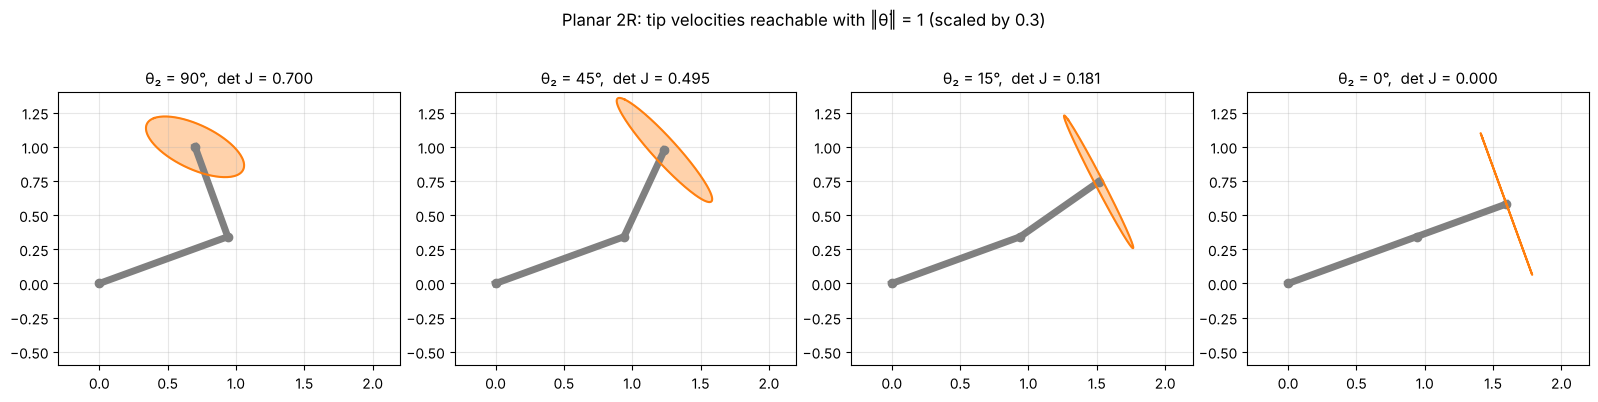

In [15]:
def ellipse_2R(theta2_list_deg, theta1_deg=20):
    t = np.linspace(0, 2 * np.pi, 200)
    unit = np.vstack([np.cos(t), np.sin(t)])           # all joint-velocity vectors of length 1
    fig, axes = plt.subplots(1, len(theta2_list_deg), figsize=(4 * len(theta2_list_deg), 4.2))
    for ax, th2 in zip(axes, theta2_list_deg):
        q = np.radians([theta1_deg, th2])
        F = robot_2R.frames(q)
        pts = np.array([F[k][:2, 3] for k in ('0', '2', 'e')])
        Jt = task_jacobian(robot_2R, q)
        E = pts[-1][:, None] + 0.3 * Jt @ unit           # tip velocities (scaled by 0.3)
        ax.plot(*pts.T, '-o', color='0.5', lw=5, ms=6)
        ax.fill(*E, color='tab:orange', alpha=0.35)
        ax.plot(*E, color='tab:orange')
        ax.set_aspect('equal'); ax.set_xlim(-0.3, 2.2); ax.set_ylim(-0.6, 1.4); ax.grid(alpha=0.3)
        ax.set_title(f'θ₂ = {th2}°,  det J = {np.linalg.det(Jt):.3f}', fontsize=11)
    fig.suptitle('Planar 2R: tip velocities reachable with ‖θ̇‖ = 1 (scaled by 0.3)', fontsize=12)
    plt.tight_layout(); plt.show()


ellipse_2R([90, 45, 15, 0])

### 6.5.2  Spherical wrist: two axes line up

$\det\mathbf{J}_\omega = -\sin\theta_2$: the wrist is singular when $\theta_2 = 0$ or
$180^\circ$. Then $\mathbf{z}_3 = \pm\mathbf{z}_1$ — the first and last joints spin about the
**same** axis, so together they provide only one rotation direction, and one direction of
angular velocity is lost. Note that the wrist's **home configuration is singular**. This is
the same *gimbal lock* you met for Euler angles in Chapter 4: the wrist's orientation is
exactly ZYZ Euler angles (Section 5.5).

<p align="center"><img src="Fig6-06_wrist_singularity.png" width="760"></p>

<p align="center"><i>Figure 6.6 — Spherical-wrist singularity. (a) At θ<sub>2</sub> = 0 the axes z<sub>1</sub> and z<sub>3</sub> are collinear, and rotation about the in-page axis perpendicular to z<sub>1</sub> and z<sub>2</sub> is lost. (b) At θ<sub>2</sub> = 90° the three axes are independent.</i></p>

In [16]:
for th2 in [0, 10, 90]:
    q = np.radians([0, th2, 0])
    F = robot_wrist.frames(q)
    print(f'θ2 = {th2:3d}°:  z1 = {np.round(F["1"][:3, 2], 3) + 0.0},  z3 = {np.round(F["3"][:3, 2], 3) + 0.0},'
          f'  rank J_ω = {np.linalg.matrix_rank(task_jacobian(robot_wrist, q), tol=1e-9)},'
          f'  det J_ω = {np.linalg.det(task_jacobian(robot_wrist, q)):+.3f}')

θ2 =   0°:  z1 = [0. 0. 1.],  z3 = [0. 0. 1.],  rank J_ω = 2,  det J_ω = +0.000
θ2 =  10°:  z1 = [0. 0. 1.],  z3 = [0.174 0.    0.985],  rank J_ω = 3,  det J_ω = -0.174
θ2 =  90°:  z1 = [0. 0. 1.],  z3 = [1. 0. 0.],  rank J_ω = 3,  det J_ω = -1.000


### 6.5.3  UR5e: shoulder, elbow and wrist singularities

Carrying the same computation through for the UR5e (by computer algebra — it takes a while,
so we only quote the result) gives a determinant that factors neatly:

$$\det\mathbf{J} = -\,a_2\,a_3\;\sin\theta_3\;\sin\theta_5\;\big(a_2c_2 + a_3c_{23} - d_5s_{234}\big).$$

Each factor is one family of singularities:

| Factor $=0$ | Name | What happens |
|---|---|---|
| $\sin\theta_3 = 0$ | **elbow** | upper arm and forearm are collinear (stretched or folded) — the 2R singularity again |
| $\sin\theta_5 = 0$ | **wrist** | axes 4 and 6 become parallel — the spherical-wrist singularity again |
| $a_2c_2 + a_3c_{23} - d_5s_{234} = 0$ | **shoulder** | the wrist point $\mathbf{o}_6$ lies in the plane of axes 1 and 2, so turning the base cannot move it sideways |

The determinant does not depend on $\theta_1$ (turning the whole arm about the base) or on
$\theta_6$ (spinning the tool). The cell below checks the formula numerically and shows one
example of each singularity.

In [17]:
def det_ur5e_formula(q, a2=0.425, a3=0.392, d5=0.100):
    c2, c23, s234 = np.cos(q[1]), np.cos(q[1] + q[2]), np.sin(q[1] + q[2] + q[3])
    return -a2 * a3 * np.sin(q[2]) * np.sin(q[4]) * (a2 * c2 + a3 * c23 - d5 * s234)


rng = np.random.default_rng(1)
Q = rng.uniform(-np.pi, np.pi, size=(200, 6))
err = max(abs(np.linalg.det(jacobian(robot_ur5e, q)) - det_ur5e_formula(q)) for q in Q)
print(f'det J vs. formula, 200 random poses: max difference = {err:.1e}')

det J vs. formula, 200 random poses: max difference = 1.1e-16


To find a shoulder singularity, pick $\theta_2$ and $\theta_3$ and solve the shoulder
condition for $\theta_4$: $\ \sin(\theta_2+\theta_3+\theta_4) = (a_2c_2 + a_3c_{23})/d_5$.

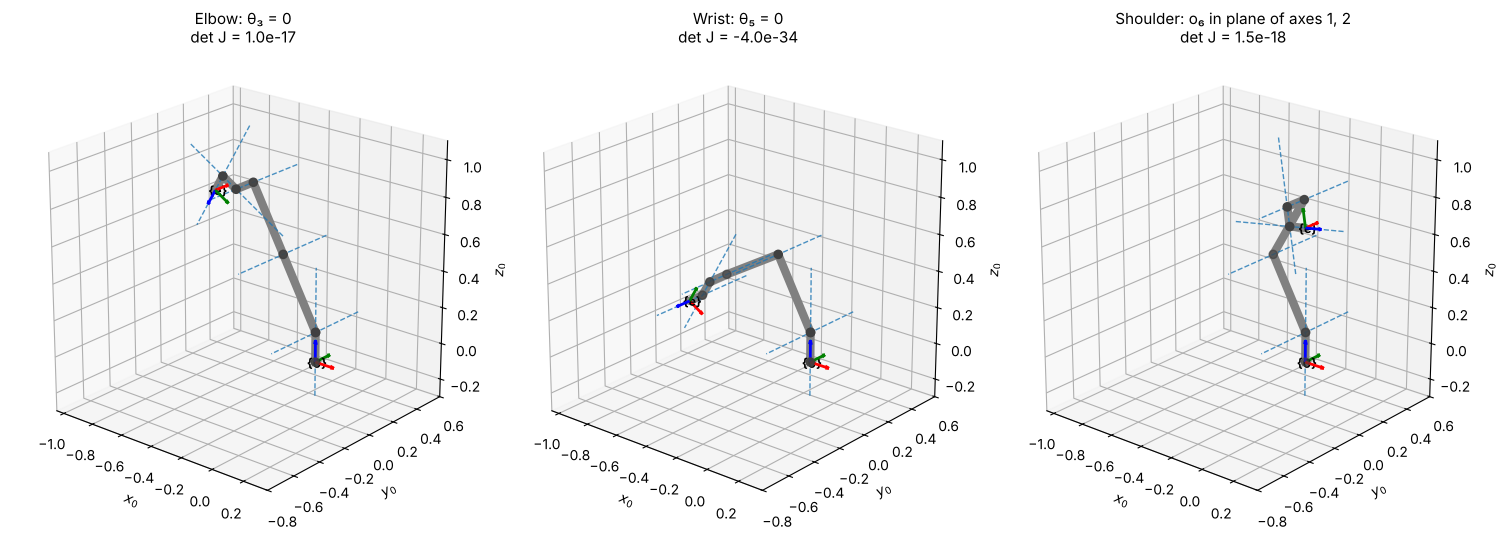

In [18]:
def shoulder_theta4(th2, th3, a2=0.425, a3=0.392, d5=0.100):
    s = (a2 * np.cos(th2) + a3 * np.cos(th2 + th3)) / d5
    return np.arcsin(s) - th2 - th3


q_elbow = np.radians([0, -60, 0, -60, -90, 0])                     # θ3 = 0
q_wrist = np.radians([0, -60, 90, -60, 0, 0])                      # θ5 = 0
th2, th3 = np.radians(-60), np.radians(-60)
q_shoulder = np.array([0, th2, th3, shoulder_theta4(th2, th3), np.radians(-90), 0])

fig = plt.figure(figsize=(15, 5.2))
for k, (q, name) in enumerate([(q_elbow, 'Elbow: θ₃ = 0'), (q_wrist, 'Wrist: θ₅ = 0'),
                               (q_shoulder, 'Shoulder: o₆ in plane of axes 1, 2')]):
    ax = fig.add_subplot(1, 3, k + 1, projection='3d')
    plot_robot(ax, robot_ur5e, q, scale=0.1, axes=True)
    d = np.linalg.det(jacobian(robot_ur5e, q))
    setup_3d(ax, title=f'{name}\ndet J = {d:.1e}', **view_ur5e)
plt.tight_layout(); plt.show()

> **Key Takeaways — Section 6.5**
> - A singularity is a configuration where the (task) Jacobian loses rank: $\det\mathbf{J} = 0$ for a square $\mathbf{J}$.
> - At a singularity some gripper velocity is impossible; near it, the joint speeds needed grow like $1/\det\mathbf{J}$.
> - 2R and SCARA: $\det\mathbf{J} = L_1L_2\sin\theta_2$ (arm stretched or folded). Spherical wrist: $\det\mathbf{J}_\omega = -\sin\theta_2$ (axes 1 and 3 aligned, gimbal lock).
> - UR5e: $\det\mathbf{J} = -a_2a_3\,s_3\,s_5\,(a_2c_2+a_3c_{23}-d_5s_{234})$ — elbow, wrist and shoulder singularities.

## 6.6  Inverse Velocity, and a First Look at Numerical Inverse Kinematics

### 6.6.1  Inverse velocity

The Jacobian answers "given $\dot{\boldsymbol\theta}$, how does the gripper move?". Very often
we need the reverse: **given a desired gripper velocity $\dot{\mathbf{x}}$, what joint
velocities produce it?** If the task Jacobian is square and not singular, just invert it:

$$\boxed{\dot{\boldsymbol\theta} = \mathbf{J}^{-1}(\boldsymbol\theta)\,\dot{\mathbf{x}}}$$

Unlike inverse *position* kinematics, this is easy: it is a linear system, with exactly one
answer. Repeating it at every time step gives **resolved-rate motion**, the standard way to
move a gripper along a straight line:

1. Measure the current $\boldsymbol\theta$ and compute the task Jacobian $\mathbf{J}(\boldsymbol\theta)$.
2. Solve $\mathbf{J}\,\dot{\boldsymbol\theta} = \dot{\mathbf{x}}_{\text{desired}}$ for $\dot{\boldsymbol\theta}$.
3. Command $\dot{\boldsymbol\theta}$ for a short time $\Delta t$: $\boldsymbol\theta \leftarrow \boldsymbol\theta + \dot{\boldsymbol\theta}\,\Delta t$. Repeat.

(In code we use `np.linalg.solve(J, xdot)`, which solves the linear system without forming
$\mathbf{J}^{-1}$ explicitly.)

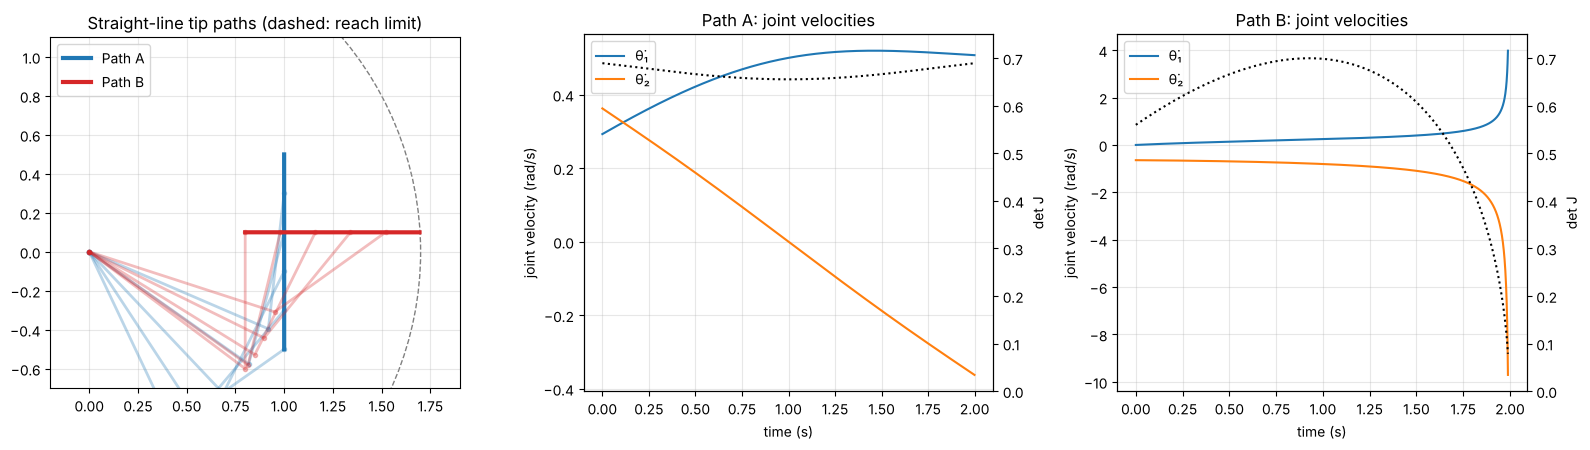

Path B: det J falls from 0.560 to 0.079; |θ̇| grows from 0.64 to 9.71 rad/s


In [19]:
def resolved_rate(robot, q0, xdot, T, dt=1e-3):
    # Move the gripper with constant task velocity xdot for T seconds.
    q = np.array(q0, float)
    log = {'t': [], 'q': [], 'qd': [], 'p': [], 'det': []}
    for k in range(int(round(T / dt))):
        Jt = task_jacobian(robot, q)               # 1. task Jacobian at the current θ
        qd = np.linalg.solve(Jt, xdot)             # 2. solve J θ̇ = ẋ
        for key, val in zip(log, (k * dt, q.copy(), qd, robot.fk(q)[:3, 3], np.linalg.det(Jt))):
            log[key].append(val)
        q = q + qd * dt                            # 3. step forward in time
    return {k: np.array(v) for k, v in log.items()}


def ik_2R(x, y, L1=1.0, L2=0.7, elbow=+1):
    # Closed-form 2R inverse kinematics from Chapter 3 (elbow=+1: θ2 > 0).
    c2 = (x**2 + y**2 - L1**2 - L2**2) / (2 * L1 * L2)
    th2 = elbow * np.arccos(np.clip(c2, -1, 1))
    th1 = np.arctan2(y, x) - np.arctan2(L2 * np.sin(th2), L1 + L2 * np.cos(th2))
    return np.array([th1, th2])


# Path A: vertical line x = 1.0, far from any singularity
A = resolved_rate(robot_2R, ik_2R(1.0, -0.5), xdot=np.array([0.0, 0.5]), T=2.0)
# Path B: radial line toward full extension, ending close to the θ2 = 0 singularity
B = resolved_rate(robot_2R, ik_2R(0.8, 0.1), xdot=np.array([0.45, 0.0]), T=1.99)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
ax = axes[0]
for run, col, name in [(A, 'tab:blue', 'Path A'), (B, 'tab:red', 'Path B')]:
    for qk in run['q'][::400]:
        F = robot_2R.frames(qk)
        pts = np.array([F[k][:2, 3] for k in ('0', '2', 'e')])
        ax.plot(*pts.T, '-o', color=col, alpha=0.3, lw=2, ms=3)
    ax.plot(*run['p'][:, :2].T, color=col, lw=3, label=name)
ax.add_patch(plt.Circle((0, 0), 1.7, fill=False, ls='--', color='0.5'))
ax.set_aspect('equal'); ax.set_xlim(-0.2, 1.9); ax.set_ylim(-0.7, 1.1); ax.grid(alpha=0.3)
ax.legend(); ax.set_title('Straight-line tip paths (dashed: reach limit)')

for ax, run, name in [(axes[1], A, 'Path A'), (axes[2], B, 'Path B')]:
    ax.plot(run['t'], run['qd'][:, 0], label='θ̇₁')
    ax.plot(run['t'], run['qd'][:, 1], label='θ̇₂')
    ax2 = ax.twinx()
    ax2.plot(run['t'], run['det'], 'k:', label='det J')
    ax2.set_ylabel('det J', color='k'); ax2.set_ylim(0, 0.75)
    ax.set_xlabel('time (s)'); ax.set_ylabel('joint velocity (rad/s)'); ax.grid(alpha=0.3)
    ax.set_title(f'{name}: joint velocities'); ax.legend(loc='upper left')
plt.tight_layout(); plt.show()

print(f'Path B: det J falls from {B["det"][0]:.3f} to {B["det"][-1]:.3f}; '
      f'|θ̇| grows from {np.abs(B["qd"][0]).max():.2f} to {np.abs(B["qd"][-1]).max():.2f} rad/s')

Path A is easy: smooth, moderate joint velocities. Path B asks the tip to move **radially**
toward full extension, which is exactly the direction lost at the $\theta_2 = 0$
singularity. As $\det\mathbf{J}\to0$ the joint velocities climb without bound; a real motor
would saturate, and the tip would fall behind or leave the line.

The same three lines of code drive the SCARA along a sloped straight line in 3D while holding
the tool's yaw fixed — the task velocity is $\dot{\mathbf{x}} = (v_x, v_y, v_z, \omega_z)$ with
$\omega_z = 0$:

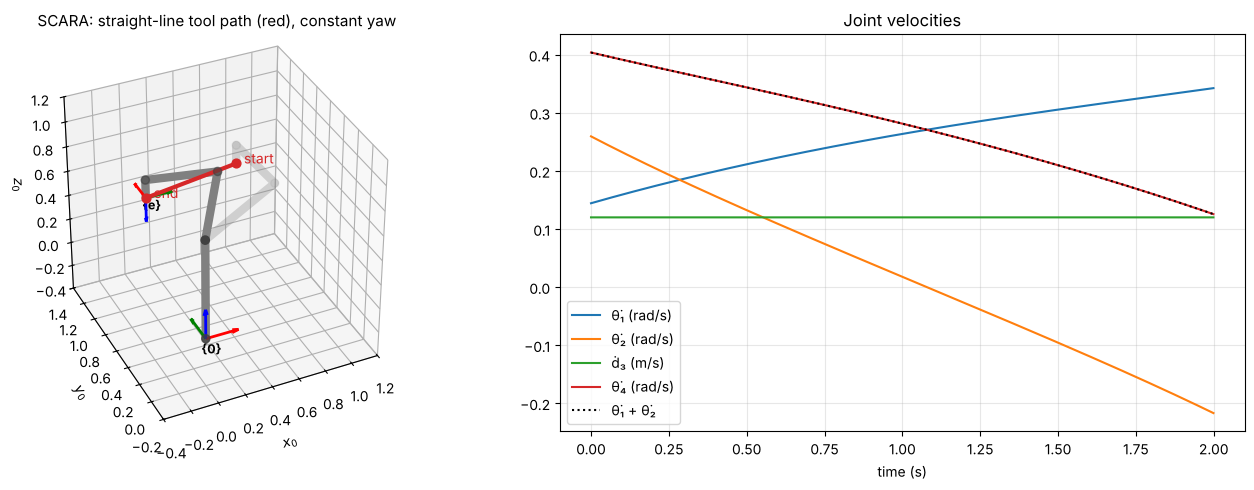

Tool yaw at start / end: 90.00° / 90.00°


In [20]:
q0 = np.array([np.radians(30), np.radians(60), 0.05, 0.0])
S = resolved_rate(robot_scara, q0, xdot=np.array([-0.30, 0.10, -0.12, 0.0]), T=2.0)

fig = plt.figure(figsize=(14, 5))
ax = fig.add_subplot(1, 2, 1, projection='3d')
plot_robot(ax, robot_scara, S['q'][0], alpha=0.3)
plot_robot(ax, robot_scara, S['q'][-1])
ax.plot(*S['p'].T, color='tab:red', lw=3, zorder=10)
ax.scatter(*S['p'][0], color='tab:red', s=40); ax.text(*S['p'][0], '  start', color='tab:red')
ax.scatter(*S['p'][-1], color='tab:red', s=40); ax.text(*S['p'][-1], '  end', color='tab:red')
setup_3d(ax, title='SCARA: straight-line tool path (red), constant yaw',
         center=(0.4, 0.6, 0.4), half=0.8, view=(35, -115))

ax = fig.add_subplot(1, 2, 2)
for i, lab in enumerate(['θ̇₁ (rad/s)', 'θ̇₂ (rad/s)', 'ḋ₃ (m/s)', 'θ̇₄ (rad/s)']):
    ax.plot(S['t'], S['qd'][:, i], label=lab)
ax.plot(S['t'], S['qd'][:, 0] + S['qd'][:, 1], 'k:', label='θ̇₁ + θ̇₂')
ax.set_xlabel('time (s)'); ax.grid(alpha=0.3); ax.legend(); ax.set_title('Joint velocities')
plt.tight_layout(); plt.show()

yaw = lambda q: q[0] + q[1] - q[3]
print(f'Tool yaw at start / end: {np.degrees(yaw(S["q"][0])):.2f}° / {np.degrees(yaw(S["q"][-1])):.2f}°')

To keep the yaw $\varphi = \theta_1+\theta_2-\theta_4$ constant, the solver automatically
turns the tool joint at $\dot\theta_4 = \dot\theta_1 + \dot\theta_2$ (the dotted line lies on
top of $\dot\theta_4$), cancelling the rotation that the arm joints would otherwise give the tool.

### 6.6.2  A first look at numerical inverse kinematics

Inverse **position** kinematics asks for the joints that put the gripper at a desired
position $\mathbf{x}_d$. In Chapter 3 we solved it with geometry for the 2R arm, but for most
robots no such closed-form solution is convenient. The Jacobian gives a general alternative.
If the gripper is at $\mathbf{x}(\boldsymbol\theta)$ and we want it at $\mathbf{x}_d$, treat the
error $\mathbf{x}_d - \mathbf{x}(\boldsymbol\theta)$ as a small displacement and use inverse
velocity to find the joint change that would produce it:

$$\boxed{\boldsymbol\theta_{k+1} = \boldsymbol\theta_k + \mathbf{J}^{-1}(\boldsymbol\theta_k)\,\big(\mathbf{x}_d - \mathbf{x}(\boldsymbol\theta_k)\big)}$$

Because the Jacobian is only a linear approximation, one step does not land exactly on the
target — but repeating the step converges very quickly (this is Newton's method).

In [21]:
def numerical_ik_2R(x_d, q0, iters=8):
    q = np.array(q0, float)
    print(f'{"k":>2}  {"θ1 (°)":>8} {"θ2 (°)":>8}   position error')
    for k in range(iters):
        err = x_d - robot_2R.fk(q)[:2, 3]
        print(f'{k:2d}  {np.degrees(q[0]):8.3f} {np.degrees(q[1]):8.3f}   {np.linalg.norm(err):.2e}')
        q = q + np.linalg.solve(task_jacobian(robot_2R, q), err)
    return q


x_d = np.array([1.2, 0.6])
print('Initial guess (20°, 60°):')
q_a = numerical_ik_2R(x_d, np.radians([20, 60]))
print('\nInitial guess (70°, -60°):')
q_b = numerical_ik_2R(x_d, np.radians([70, -60]))

print('\nClosed-form IK (Chapter 3):')
for elbow in (+1, -1):
    print(f'  elbow {elbow:+d}: θ = {np.round(np.degrees(ik_2R(*x_d, elbow=elbow)), 3)}°')

Initial guess (20°, 60°):
 k    θ1 (°)   θ2 (°)   position error
 0    20.000   60.000   4.53e-01
 1    -6.513   88.134   1.07e-01
 2    -4.455   77.772   7.44e-03
 3    -4.019   77.210   2.94e-05
 4    -4.019   77.207   6.54e-10
 5    -4.019   77.207   1.11e-16
 6    -4.019   77.207   0.00e+00
 7    -4.019   77.207   0.00e+00

Initial guess (70°, -60°):
 k    θ1 (°)   θ2 (°)   position error
 0    70.000  -60.000   4.91e-01
 1    64.313  -89.827   1.35e-01
 2    57.351  -78.057   7.95e-03
 3    57.152  -77.211   4.63e-05
 4    57.149  -77.207   1.16e-09
 5    57.149  -77.207   1.11e-16
 6    57.149  -77.207   1.11e-16
 7    57.149  -77.207   1.11e-16

Closed-form IK (Chapter 3):
  elbow +1: θ = [-4.019 77.207]°
  elbow -1: θ = [ 57.149 -77.207]°


In a handful of iterations the error drops to machine precision, and the two initial guesses
converge to the two elbow solutions of Chapter 3 — numerical IK finds **one** solution, the
one "closest" to where it starts. The same update works for the SCARA or the UR5e with
their task Jacobians. Making it robust — handling orientation targets, non-square
Jacobians, and the singularities of Section 6.5 (where $\mathbf{J}^{-1}$ does not exist) —
is the subject of the inverse kinematics chapter.

> **Key Takeaways — Section 6.6**
> - Inverse velocity is a linear solve: $\dot{\boldsymbol\theta} = \mathbf{J}^{-1}\dot{\mathbf{x}}$ (square, non-singular task Jacobian).
> - Resolved-rate motion repeats that solve every time step to drive the gripper along a straight line or hold an orientation.
> - Near a singularity the required joint velocities blow up.
> - Iterating $\boldsymbol\theta \leftarrow \boldsymbol\theta + \mathbf{J}^{-1}(\mathbf{x}_d - \mathbf{x}(\boldsymbol\theta))$ solves inverse position kinematics numerically; the answer depends on the initial guess.

## 6.7  Statics: $\boldsymbol\tau = \mathbf{J}^\top\mathbf{F}$

The Jacobian also tells us how **forces** pass through the arm. Suppose the gripper pushes on
its surroundings with a force $\mathbf{f}$ and a moment $\mathbf{n}$, collected in the
**wrench** $\mathbf{F} = [\mathbf{f};\ \mathbf{n}]$ (both in frame $\{0\}$). What joint torques
$\boldsymbol\tau$ (forces, for prismatic joints) must the motors supply to hold it, with the
arm at rest?

Use power. Imagine a tiny motion $\dot{\boldsymbol\theta}$. The motors deliver power
$\boldsymbol\tau^\top\dot{\boldsymbol\theta}$; the gripper delivers power
$\mathbf{f}^\top\mathbf{v} + \mathbf{n}^\top\boldsymbol\omega = \mathbf{F}^\top\mathbf{J}\dot{\boldsymbol\theta}$
to the surroundings. Without friction (and ignoring the links' own weight) the two must be
equal for **every** $\dot{\boldsymbol\theta}$, so

$$\boxed{\boldsymbol\tau = \mathbf{J}^\top(\boldsymbol\theta)\,\mathbf{F}}$$

The same matrix that maps joint velocities *out* to gripper velocity maps gripper wrench
*back* to joint torques — transposed. Note there is no inverse here, so statics is well
defined even at a singularity.

### Example: the 2R arm holding a payload

Turn the 2R arm so that it moves in a **vertical** plane, with gravity along $-y_0$. To hold a
payload of mass $m$, the gripper must push up on it: $\mathbf{f} = (0,\ mg,\ 0)$, $\mathbf{n} = \mathbf{0}$.
Then

$$\boldsymbol\tau = \mathbf{J}^\top\mathbf{F} = \begin{bmatrix} mg\,(L_1c_1+L_2c_{12})\\ mg\,L_2c_{12}\end{bmatrix} ,$$

each torque being the weight times the horizontal distance from that joint to the payload —
the familiar "force × lever arm".

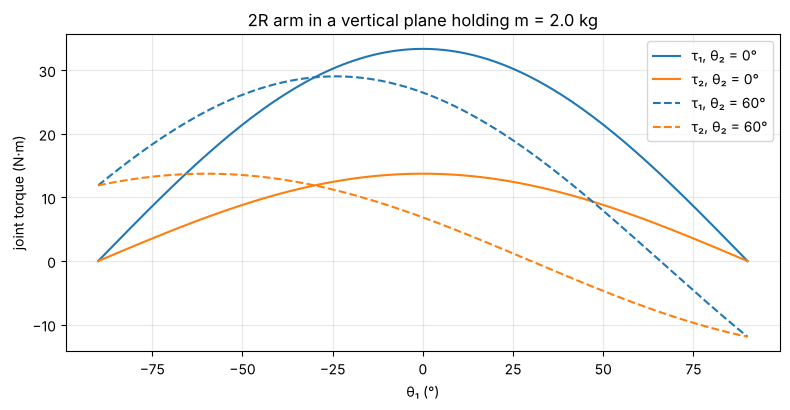

Worst case (arm horizontal, θ = (0, 0)): τ = [33.35 13.73] N·m
Arm pointing straight up, θ = (90°, 0):  τ = [0. 0.] N·m


In [22]:
m, g = 2.0, 9.81
F_wrench = np.array([0, m * g, 0, 0, 0, 0])

th1 = np.radians(np.linspace(-90, 90, 181))
fig, ax = plt.subplots(figsize=(8, 4.2))
for th2_deg, ls in [(0, '-'), (60, '--')]:
    tau = np.array([jacobian(robot_2R, [t, np.radians(th2_deg)]).T @ F_wrench for t in th1])
    ax.plot(np.degrees(th1), tau[:, 0], ls, color='tab:blue', label=f'τ₁, θ₂ = {th2_deg}°')
    ax.plot(np.degrees(th1), tau[:, 1], ls, color='tab:orange', label=f'τ₂, θ₂ = {th2_deg}°')
ax.set_xlabel('θ₁ (°)'); ax.set_ylabel('joint torque (N·m)'); ax.grid(alpha=0.3); ax.legend()
ax.set_title(f'2R arm in a vertical plane holding m = {m} kg')
plt.tight_layout(); plt.show()

tau_max = jacobian(robot_2R, [0, 0]).T @ F_wrench
print(f'Worst case (arm horizontal, θ = (0, 0)): τ = {np.round(tau_max[:2], 2)} N·m')
print(f'Arm pointing straight up, θ = (90°, 0):  τ = {np.round((jacobian(robot_2R, np.radians([90, 0])).T @ F_wrench)[:2], 2) + 0.0} N·m')

The worst case — arm stretched out horizontally — sets the torque the motors must be sized
for (Chapter 2). With the arm pointing straight up the joints need **no** torque: the arm is
at the $\theta_2 = 0$ singularity, and the load acts along the lost (radial) direction, where
the links themselves carry it. Singularities are bad for motion, but good for carrying load.

### Example: SCARA pressing and screwing

A SCARA driving a screw pushes down with 20 N while applying 0.5 N·m of tightening moment
(clockwise seen from above, so $n_z = -0.5$):

In [23]:
q = [np.radians(30), np.radians(45), 0.2, np.radians(-60)]
F_wrench = np.array([0, 0, -20.0, 0, 0, -0.5])            # [f; n] applied by the tool
tau = jacobian(robot_scara, q).T @ F_wrench
for (label, _, jtype, _), t in zip(robot_scara.joints, tau):
    print(f'  {label}: {t:+.2f} {"N·m" if jtype == "R" else "N"}')

  θ₁: -0.50 N·m
  θ₂: -0.50 N·m
  d₃: +20.00 N
  θ₄: +0.50 N·m


The 20 N push is carried entirely by the quill ($f_3 = 20$ N) — joints 1 and 2 feel none of
it, because their axes are vertical. The moment about the vertical is reacted by **every**
revolute joint with a vertical axis: $\tau_1 = \tau_2 = n_z$ and $\tau_4 = -n_z$ (sign flipped
because $\mathbf{z}_4$ points down). This is the SCARA's "selective compliance": stiff
vertically, compliant in the horizontal plane.

> **Key Takeaways — Section 6.7**
> - Joint torques that hold a gripper wrench $\mathbf{F} = [\mathbf{f};\mathbf{n}]$: $\boldsymbol\tau = \mathbf{J}^\top\mathbf{F}$ (from equal power at the joints and at the gripper).
> - Each torque is a "force × lever arm" about that joint's axis.
> - At a singularity, loads along the lost direction need no joint torque.

## Chapter 6 Summary

> - **The Jacobian** maps joint velocities to gripper velocity: $[\mathbf{v};\boldsymbol\omega] = \mathbf{J}(\boldsymbol\theta)\,\dot{\boldsymbol\theta}$, $\mathbf{J}\in\mathbb{R}^{6\times n}$.
> - **Column formula**, with $\mathbf{z}_i$, $\mathbf{o}_i$ from $\mathbf{T}_i^0$ and $\mathbf{o}_e$ from $\mathbf{T}_e^0$:
>   revolute $\mathbf{J}_i = [\mathbf{z}_i\times(\mathbf{o}_e-\mathbf{o}_i);\ \mathbf{z}_i]$, prismatic $\mathbf{J}_i = [\mathbf{z}_i;\ \mathbf{0}]$.
> - **Why:** one joint moving is a rotation about (or a slide along) its axis, $\mathbf{v} = \boldsymbol\omega\times\mathbf{r}$; contributions of all joints add.
> - **Singularities:** the task Jacobian loses rank ($\det\mathbf{J}=0$); a gripper direction is lost and nearby joint speeds blow up.
> - **Inverse velocity:** $\dot{\boldsymbol\theta} = \mathbf{J}^{-1}\dot{\mathbf{x}}$; iterated, it becomes numerical inverse kinematics.
> - **Statics:** $\boldsymbol\tau = \mathbf{J}^\top\mathbf{F}$.

| Robot | Task rows | $\det\mathbf{J}_{task}$ | Singular when |
|---|---|---|---|
| Planar 2R | $v_x, v_y$ | $L_1L_2\sin\theta_2$ | arm stretched or folded |
| Spherical wrist | $\omega_x,\omega_y,\omega_z$ | $-\sin\theta_2$ | axes 1 and 3 aligned |
| SCARA | $v_x, v_y, v_z, \omega_z$ | $L_1L_2\sin\theta_2$ | arm stretched or folded |
| UR5e | all six | $-a_2a_3\,s_3\,s_5\,(a_2c_2+a_3c_{23}-d_5s_{234})$ | elbow, wrist, shoulder |